In [1]:
import sys

sys.path.append("../..")

from datetime import date
import polars as pl

from etl.transformation.gold import StocksMlReadyGold
from analysis.strategies.classic_momentum import ClassicMomentum
from analysis.strategies.adaptive_momentum import AdaptiveMomentum
from analysis.strategies.reporting import plot_result




In [ ]:
START = date(2015, 1, 1)
END = date(2025, 1, 1)

df = StocksMlReadyGold(dataplatform_root="../../dataplatform")\
    .read_from_disk()\
    .filter(pl.col("timeframe").is_between(START, END, closed="left"))\
    .select(['timeframe', 'symbol', 'open', 'close', 'high', 'low'])\
    .collect()



[21:34:01] gold.stocks_ml_ready is of VIEW kind and cannot be read from disk, defaulting to .build() call
[21:34:01] Building from source data model gold.stocks_ml_ready
[21:34:01] gold.stocks_ml_ready build plan ready and validated


/tmp/ipykernel_105248/628507333.py:14: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  .collect()


2017-01-30: optimized params {'months_lookback': 3, 'weeks_ignore': 4, 'top_n': 20, 'rebalance': 'weekly'}
2017-02-06: optimized params {'months_lookback': 3, 'weeks_ignore': 4, 'top_n': 10, 'rebalance': 'quarterly'}
2017-02-13: optimized params {'months_lookback': 3, 'weeks_ignore': 4, 'top_n': 30, 'rebalance': 'weekly'}
2017-02-21: optimized params {'months_lookback': 3, 'weeks_ignore': 4, 'top_n': 30, 'rebalance': 'weekly'}
2017-02-27: optimized params {'months_lookback': 3, 'weeks_ignore': 4, 'top_n': 30, 'rebalance': 'weekly'}
2017-03-06: optimized params {'months_lookback': 3, 'weeks_ignore': 4, 'top_n': 20, 'rebalance': 'weekly'}
2017-03-13: optimized params {'months_lookback': 3, 'weeks_ignore': 4, 'top_n': 20, 'rebalance': 'weekly'}
2017-03-20: optimized params {'months_lookback': 9, 'weeks_ignore': 4, 'top_n': 10, 'rebalance': 'weekly'}
2017-03-27: optimized params {'months_lookback': 9, 'weeks_ignore': 4, 'top_n': 10, 'rebalance': 'weekly'}
2017-04-03: optimized params {'mon

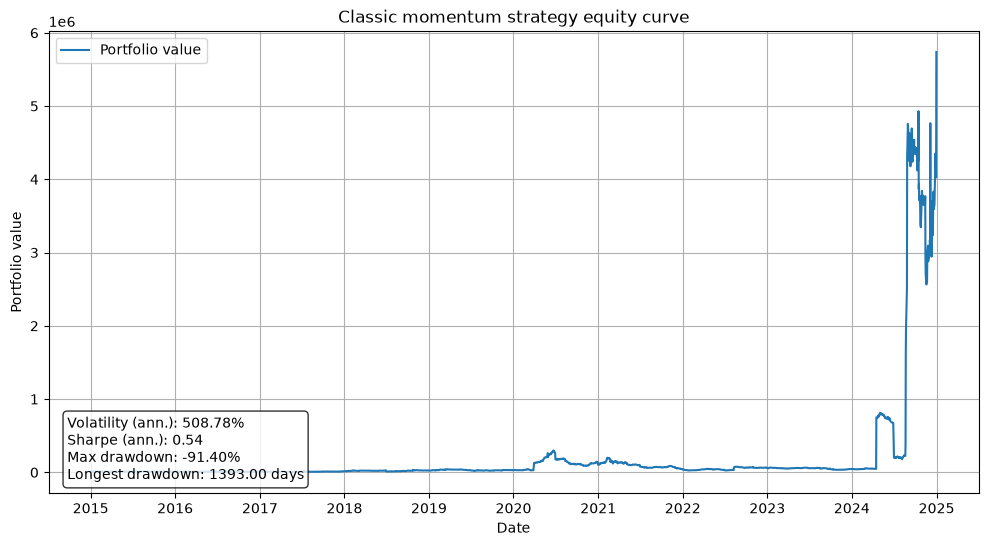

In [3]:
strat = AdaptiveMomentum(
    reoptimize='weekly',
)
history = strat.daily_backtest(df, 10_000, log_on_mlflow=True)
plot_result(history)

2017-01-30: optimized params {'months_lookback': 3, 'weeks_ignore': 4, 'top_n': 20, 'rebalance': 'weekly'}
2017-02-01: optimized params {'months_lookback': 3, 'weeks_ignore': 4, 'top_n': 30, 'rebalance': 'weekly'}
2017-03-01: optimized params {'months_lookback': 3, 'weeks_ignore': 4, 'top_n': 20, 'rebalance': 'weekly'}
2017-04-03: optimized params {'months_lookback': 9, 'weeks_ignore': 4, 'top_n': 10, 'rebalance': 'weekly'}
2017-05-01: optimized params {'months_lookback': 9, 'weeks_ignore': 4, 'top_n': 10, 'rebalance': 'weekly'}
2017-06-01: optimized params {'months_lookback': 9, 'weeks_ignore': 4, 'top_n': 10, 'rebalance': 'weekly'}
2017-07-03: optimized params {'months_lookback': 12, 'weeks_ignore': 4, 'top_n': 10, 'rebalance': 'weekly'}
2017-08-01: optimized params {'months_lookback': 3, 'weeks_ignore': 4, 'top_n': 10, 'rebalance': 'quarterly'}
2017-09-01: optimized params {'months_lookback': 9, 'weeks_ignore': 2, 'top_n': 10, 'rebalance': 'weekly'}
2017-10-02: optimized params {'mo

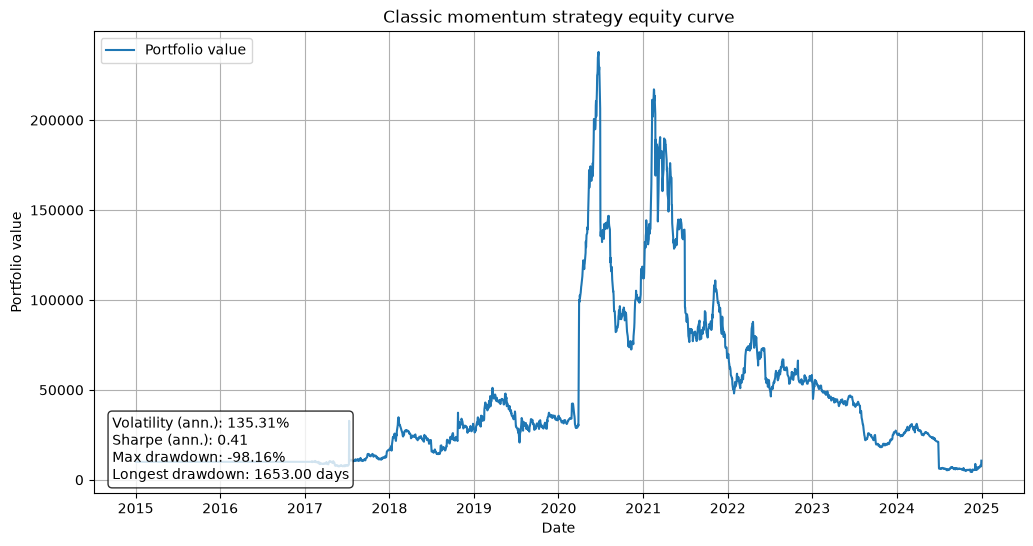

In [4]:
strat = AdaptiveMomentum(
    reoptimize='monthly',
)
history = strat.daily_backtest(df, 10_000, log_on_mlflow=True)
plot_result(history)

2017-01-30: optimized params {'months_lookback': 3, 'weeks_ignore': 4, 'top_n': 20, 'rebalance': 'weekly'}
2017-04-03: optimized params {'months_lookback': 9, 'weeks_ignore': 4, 'top_n': 10, 'rebalance': 'weekly'}
2017-07-03: optimized params {'months_lookback': 12, 'weeks_ignore': 4, 'top_n': 10, 'rebalance': 'weekly'}
2017-10-02: optimized params {'months_lookback': 9, 'weeks_ignore': 2, 'top_n': 10, 'rebalance': 'weekly'}
2018-01-02: optimized params {'months_lookback': 9, 'weeks_ignore': 2, 'top_n': 10, 'rebalance': 'weekly'}
2018-04-02: optimized params {'months_lookback': 9, 'weeks_ignore': 2, 'top_n': 10, 'rebalance': 'weekly'}
2018-07-02: optimized params {'months_lookback': 9, 'weeks_ignore': 2, 'top_n': 30, 'rebalance': 'weekly'}
2018-10-01: optimized params {'months_lookback': 3, 'weeks_ignore': 2, 'top_n': 10, 'rebalance': 'weekly'}
2019-01-02: optimized params {'months_lookback': 3, 'weeks_ignore': 2, 'top_n': 10, 'rebalance': 'weekly'}
2019-04-01: optimized params {'month

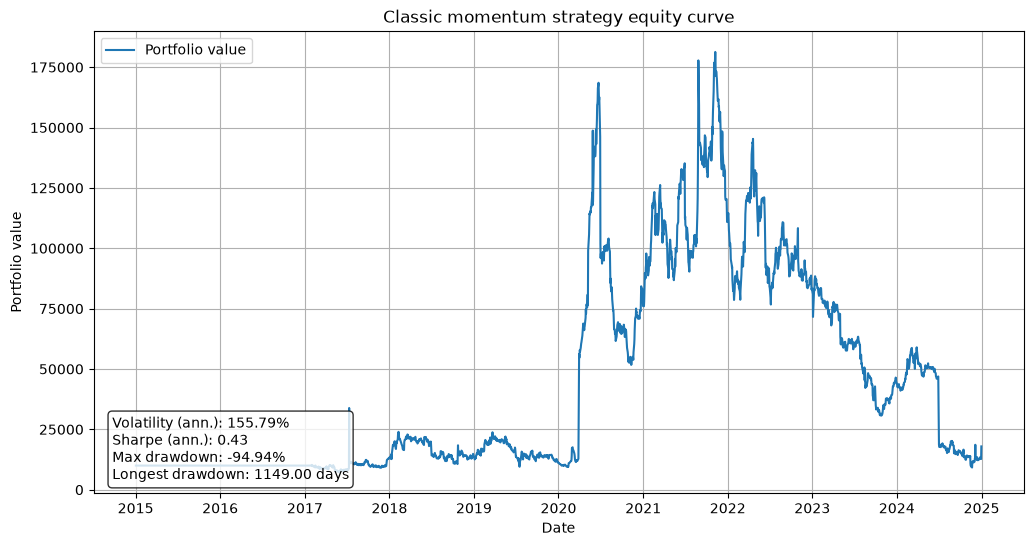

In [5]:
strat = AdaptiveMomentum(
    reoptimize='quarterly',
)
history = strat.daily_backtest(df, 10_000, log_on_mlflow=True)
plot_result(history)